# Python Project 2 — An Exploration of Public Health Data (Diabetes)

**Susana Rivera** — Python Analytics Class — September 2026

**Option 1: public health data.** This dataset has 101,766 hospital visits by diabetes patients at 130 US hospitals over ten years (1999-2008). Each row is one hospital stay.

**My plan:**

- **Group I picked:** patients aged **70 to 80**, the largest age group in the data.
- **Measure I picked:** **time in hospital** (number of days the patient stayed).
- **Comparison group:** patients aged **30 to 40**, to see how much age changes the length of a diabetes-related hospital stay.
- As a bonus I also look at how many medications each group takes and how often they come back to the hospital within 30 days.

The notebook has descriptive statistics, several cleaning steps, three charts, and a brief conclusion.

## 1. Load the data

I import pandas and matplotlib and read the CSV straight from GitHub. The file is big (about 19 MB), so it may take a few seconds.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Make every chart use large text so it is easy to read
plt.rcParams.update({'font.size': 14, 'figure.figsize': (10, 6)})

url = 'https://raw.githubusercontent.com/niteen11/DataAnalyticsAcademy/master/Python/dataset_diabetes/diabetic_data.csv'
df = pd.read_csv(url, low_memory=False)

## 2. Understand the data first

`head()`, `shape`, and `describe()` give me a first look. The dataset has 50 columns, so I also print the column names to see what is available.

In [2]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.shape

(101766, 50)

In [4]:
list(df.columns)

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

In [5]:
df[['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_diagnoses']].describe().round(1)

,time_in_hospital,num_lab_procedures,num_medications,number_diagnoses
count,101766.0,101766.0,101766.0,101766.0
mean,4.4,43.1,16.0,7.4
std,3.0,19.7,8.1,1.9
min,1.0,1.0,1.0,1.0
25%,2.0,31.0,10.0,6.0
50%,4.0,44.0,15.0,8.0
75%,6.0,57.0,20.0,9.0
max,14.0,132.0,81.0,16.0


In [6]:
print(df['age'].value_counts().sort_index())
print()
print(df['gender'].value_counts())
print()
print(df['readmitted'].value_counts())

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


## 3. Cleaning the data

Looking at the data, I found several problems. I fix each one:

1. **Missing values are written as a question mark ("?")**, not left blank, so pandas does not know they are missing. I replace "?" with `NaN`.
2. **Three columns are almost entirely missing** (`weight`, `payer_code`, `medical_specialty`). I drop them.
3. **Three rows have gender "Unknown/Invalid".** I remove them.
4. **The age labels look like `[70-80)`**, which is a math notation that is hard to read. I clean them to `70 to 80`.

In [7]:
# Task 1 — count the "?" values in each column, then turn them into real missing values (NaN)
question_marks = (df == '?').sum()
print(question_marks[question_marks > 0])

df = df.replace('?', pd.NA)

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64


In [8]:
# Task 2 — drop the columns that are mostly missing
df = df.drop(columns=['weight', 'payer_code', 'medical_specialty'])
print(f'{df.shape[1]} columns remain.')

47 columns remain.


In [9]:
# Task 3 — remove the 3 rows with an unknown gender
before = len(df)
df = df[df['gender'] != 'Unknown/Invalid']
print(f'Removed {before - len(df)} rows. {len(df):,} rows remain.')

Removed 3 rows. 101,763 rows remain.


In [10]:
# Task 4 — make the age labels readable:  "[70-80)"  ->  "70 to 80"
df['age'] = df['age'].str.strip('[)').str.replace('-', ' to ')
sorted(df['age'].unique())

['0 to 10',
 '10 to 20',
 '20 to 30',
 '30 to 40',
 '40 to 50',
 '50 to 60',
 '60 to 70',
 '70 to 80',
 '80 to 90',
 '90 to 100']

In [11]:
# Check that the missing values are now counted properly
df.isna().sum()[df.isna().sum() > 0]

race              2271
diag_1              21
diag_2             358
diag_3            1423
max_glu_serum    96417
A1Cresult        84745
dtype: int64

## 4. My two groups

I filter the data into two smaller dataframes: `older` (age 70 to 80) and `younger` (age 30 to 40).

In [12]:
older = df[df['age'] == '70 to 80']
younger = df[df['age'] == '30 to 40']

print(f'Patients aged 70 to 80: {len(older):,} hospital stays')
print(f'Patients aged 30 to 40: {len(younger):,} hospital stays')

Patients aged 70 to 80: 26,066 hospital stays
Patients aged 30 to 40: 3,775 hospital stays


## 5. Descriptive statistics

### Time in hospital — age 70 to 80

In [13]:
older['time_in_hospital'].describe().round(2)

count    26066.00
mean         4.59
std          3.04
min          1.00
25%          2.00
50%          4.00
75%          6.00
max         14.00
Name: time_in_hospital, dtype: float64

### Time in hospital — age 30 to 40

In [14]:
younger['time_in_hospital'].describe().round(2)

count    3775.00
mean        3.80
std         2.69
min         1.00
25%         2.00
50%         3.00
75%         5.00
max        14.00
Name: time_in_hospital, dtype: float64

### Side-by-side comparison

I put the two groups in one table so the difference is easy to see. I also add two bonus measures: the average number of medications, and the percent of patients readmitted to the hospital within 30 days.

In [15]:
def summarize(group, name):
    return pd.Series({
        'hospital stays': len(group),
        'average days in hospital': group['time_in_hospital'].mean(),
        'median days in hospital': group['time_in_hospital'].median(),
        'longest stay (days)': group['time_in_hospital'].max(),
        'average number of medications': group['num_medications'].mean(),
        'average number of diagnoses': group['number_diagnoses'].mean(),
        'percent readmitted within 30 days': (group['readmitted'] == '<30').mean() * 100,
    }, name=name)

comparison = pd.concat([summarize(older, 'Age 70 to 80'), summarize(younger, 'Age 30 to 40')], axis=1).round(1)
comparison

,Age 70 to 80,Age 30 to 40
hospital stays,26066.0,3775.0
average days in hospital,4.6,3.8
median days in hospital,4.0,3.0
longest stay (days),14.0,14.0
average number of medications,16.4,14.1
average number of diagnoses,7.7,6.5
percent readmitted within 30 days,11.8,11.2


### Every age group at once

`groupby('age')` shows the pattern across all ten age groups, not just my two.

In [16]:
by_age = df.groupby('age').agg(
    stays=('time_in_hospital', 'size'),
    avg_days=('time_in_hospital', 'mean'),
    avg_medications=('num_medications', 'mean'),
).round(2)
by_age

,stays,avg_days,avg_medications
age,,,
0 to 10,161,2.55,6.18
10 to 20,691,3.19,8.28
20 to 30,1657,3.56,11.97
30 to 40,3775,3.80,14.09
40 to 50,9685,4.04,15.39
50 to 60,17256,4.13,16.58
60 to 70,22482,4.38,17.15
70 to 80,26066,4.59,16.41
80 to 90,17197,4.81,15.33


## 6. Visualizations

### Chart 1 — Average days in hospital by age group

My two groups are highlighted in color; the other age groups are gray.

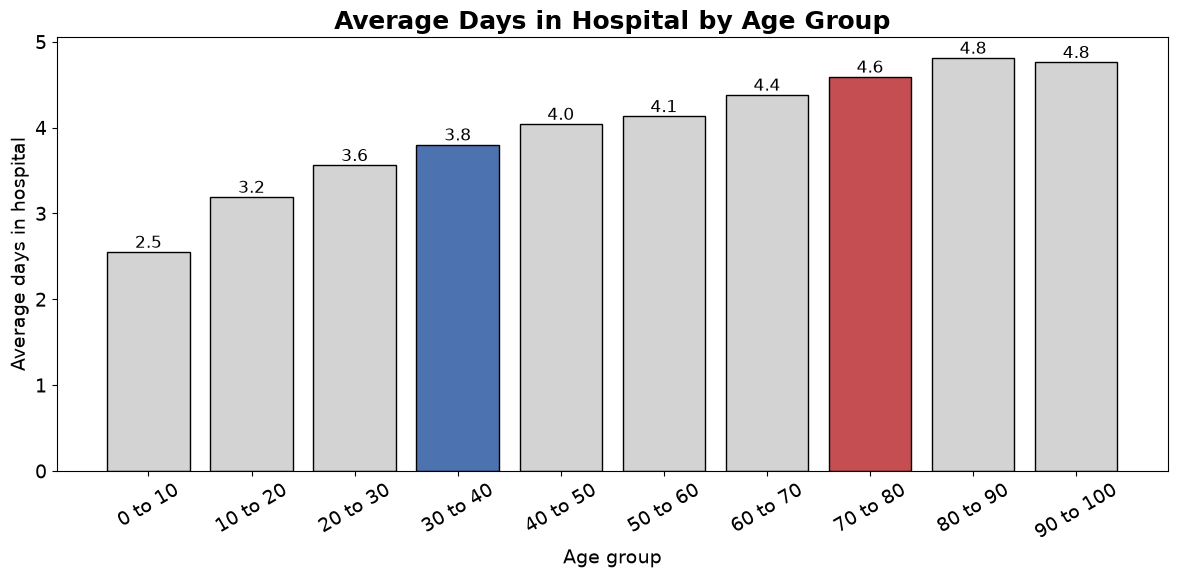

In [17]:
colors = ['#C44E52' if age == '70 to 80' else '#4C72B0' if age == '30 to 40' else 'lightgray' for age in by_age.index]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(by_age.index, by_age['avg_days'], color=colors, edgecolor='black')
ax.set_title('Average Days in Hospital by Age Group', fontsize=18, fontweight='bold')
ax.set_xlabel('Age group')
ax.set_ylabel('Average days in hospital')
for bar, value in zip(bars, by_age['avg_days']):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.05, f'{value:.1f}', ha='center', fontsize=12)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Chart 2 — How long do stays last in each group?

A histogram shows what share of each group stayed 1 day, 2 days, and so on. Using percentages instead of counts makes the two groups fair to compare even though the older group is seven times bigger.

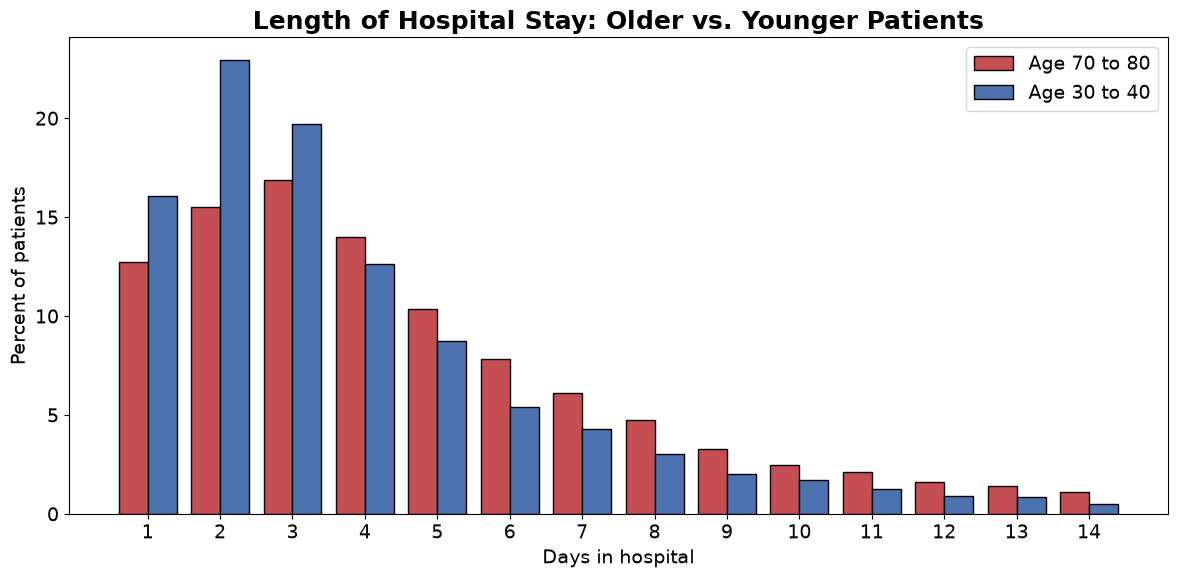

In [18]:
days = range(1, 15)

older_pct = older['time_in_hospital'].value_counts(normalize=True).sort_index() * 100
younger_pct = younger['time_in_hospital'].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(12, 6))
width = 0.4
ax.bar([d - width / 2 for d in days], [older_pct.get(d, 0) for d in days], width, label='Age 70 to 80', color='#C44E52', edgecolor='black')
ax.bar([d + width / 2 for d in days], [younger_pct.get(d, 0) for d in days], width, label='Age 30 to 40', color='#4C72B0', edgecolor='black')
ax.set_title('Length of Hospital Stay: Older vs. Younger Patients', fontsize=18, fontweight='bold')
ax.set_xlabel('Days in hospital')
ax.set_ylabel('Percent of patients')
ax.set_xticks(list(days))
ax.legend()
plt.tight_layout()
plt.show()

### Chart 3 — Medications and readmissions

Two small bar charts side by side for the bonus measures.

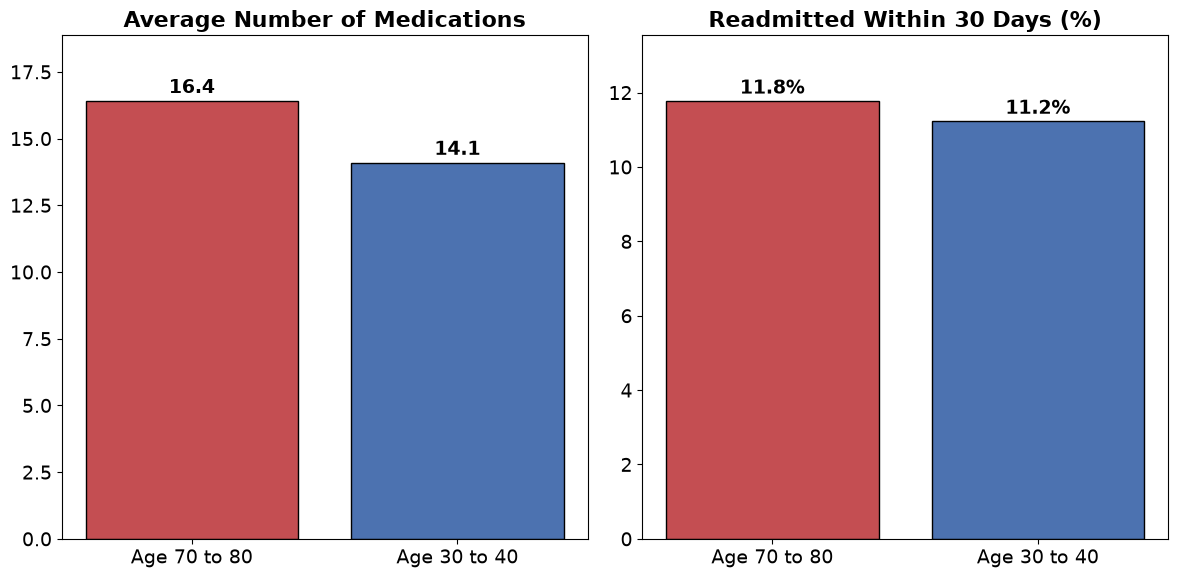

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

meds = [older['num_medications'].mean(), younger['num_medications'].mean()]
ax1.bar(['Age 70 to 80', 'Age 30 to 40'], meds, color=['#C44E52', '#4C72B0'], edgecolor='black')
ax1.set_title('Average Number of Medications', fontsize=16, fontweight='bold')
for i, v in enumerate(meds):
    ax1.text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=14, fontweight='bold')

readmit = [(older['readmitted'] == '<30').mean() * 100, (younger['readmitted'] == '<30').mean() * 100]
ax2.bar(['Age 70 to 80', 'Age 30 to 40'], readmit, color=['#C44E52', '#4C72B0'], edgecolor='black')
ax2.set_title('Readmitted Within 30 Days (%)', fontsize=16, fontweight='bold')
for i, v in enumerate(readmit):
    ax2.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=14, fontweight='bold')

# leave a little room above the bars for the labels
ax1.set_ylim(0, max(meds) * 1.15)
ax2.set_ylim(0, max(readmit) * 1.15)

plt.tight_layout()
plt.show()

## 7. Conclusion

Older diabetes patients stay in the hospital longer than younger ones. Patients aged 70 to 80 averaged 4.6 days per stay, compared with 3.8 days for patients aged 30 to 40, and Chart 1 shows the average climbs steadily with every age group. The older group also takes more medications on average (16.4 vs. 14.1) and has a slightly higher chance of being readmitted within 30 days (11.8% vs. 11.2%). Chart 2 shows why the averages differ: a much larger share of younger patients go home after just one or two days, while older patients are more likely to stay a week or longer. The cleaning steps mattered here too, because missing values were hidden as question marks and would have been counted as real data if I had not replaced them.